**Лабораторная работа №3**  
Дисциплина: Системы искусственного интеллекта и машинное обучение

### Автор
* **ФИО:** Коваленко Евгений Алексеевич
* **Группа:** АП-327

**Датасет:** Credit card Dataset

**Датасет** содержит в себе информацию о поведении и характеристику пользователей кредитных банковских карт в течении 6 месяцев, включая их баланс, количество покупок, выплаты пользователя и так далее.

**Цель работы**: изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

**Постановка задачи:**

1. Загрузить датасет для задачи кластеризации. Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.
2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.
3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.
4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.
5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.
6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.



In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

In [2]:
df_raw = pd.read_csv('../data/CC_GENERAL.csv')
rows, cols = df_raw.shape
print(f"Размерность исходного датасета: {rows} строк (клиентов) и {cols} признаков.")
display(df_raw.head(3))
display(df_raw.info())

Размерность исходного датасета: 8950 строк (клиентов) и 18 признаков.


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.0,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.0,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.0,0.000000,0.00,0,12,7500.0,622.066742,627.284787,0.000000,12


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

None

- Датасет содержит **8 950 строк** (уникальных профилей держателей кредитных карт) и **18 столбцов**.
- **Типы данных:** 17 признаков являются числовыми (количественные финансовые метрики, из них 14 с плавающей точкой `float64` и 3 целочисленных `int64`). Признак `CUST_ID` является строковым (`object`) идентификатором клиента, не несет физического смысла и подлежит удалению перед этапом вычисления метрик расстояния.

In [4]:
missing_info = df_raw.isnull().sum()
missing_table = pd.DataFrame({
    'Количество пропусков': missing_info[missing_info > 0],
})

display(missing_table)

,Количество пропусков
CREDIT_LIMIT,1
MINIMUM_PAYMENTS,313


- Обнаружены пропуски в двух признаках:
  - `CREDIT_LIMIT`: 1 пропущенное значение.
  - `MINIMUM_PAYMENTS`: 313 пропущенных значений.
- **Обоснование метода заполнения:** Очевидно, что удаление 313 строк при общем количестве в 8950 приведет к неоправданной потере информации о клиентской базе. Вместо этого пропуски будут заполнены медианным значением.

In [5]:
df_cleaned = df_raw.copy()

df_cleaned.drop(columns=['CUST_ID'], inplace=True)
df_cleaned['CREDIT_LIMIT'].fillna(df_cleaned['CREDIT_LIMIT'].median(), inplace=True)
df_cleaned['MINIMUM_PAYMENTS'].fillna(df_cleaned['MINIMUM_PAYMENTS'].median(), inplace=True)

print(f"Остаток пропущенных значений после импутации: {df_cleaned.isnull().sum().sum()}")
print(f"Размерность очищенного датасета: {df_cleaned.shape}")

Остаток пропущенных значений после импутации: 0
Размерность очищенного датасета: (8950, 17)


1. Идентификатор `CUST_ID` успешно удален. Пространство признаков сократилось до 17 чисто числовых метрик поведения.
2. Пропущенные значения в `CREDIT_LIMIT` и `MINIMUM_PAYMENTS` заполнены медианами по столбцам, целостность массива данных полностью восстановлена без потери наблюдений.

,Коэффициент асимметрии (Skewness)
MINIMUM_PAYMENTS,13.85
ONEOFF_PURCHASES,10.05
PURCHASES,8.14
INSTALLMENTS_PURCHASES,7.30
PAYMENTS,5.91
CASH_ADVANCE_TRX,5.72
CASH_ADVANCE,5.17
PURCHASES_TRX,4.63
BALANCE,2.39
PRC_FULL_PAYMENT,1.94


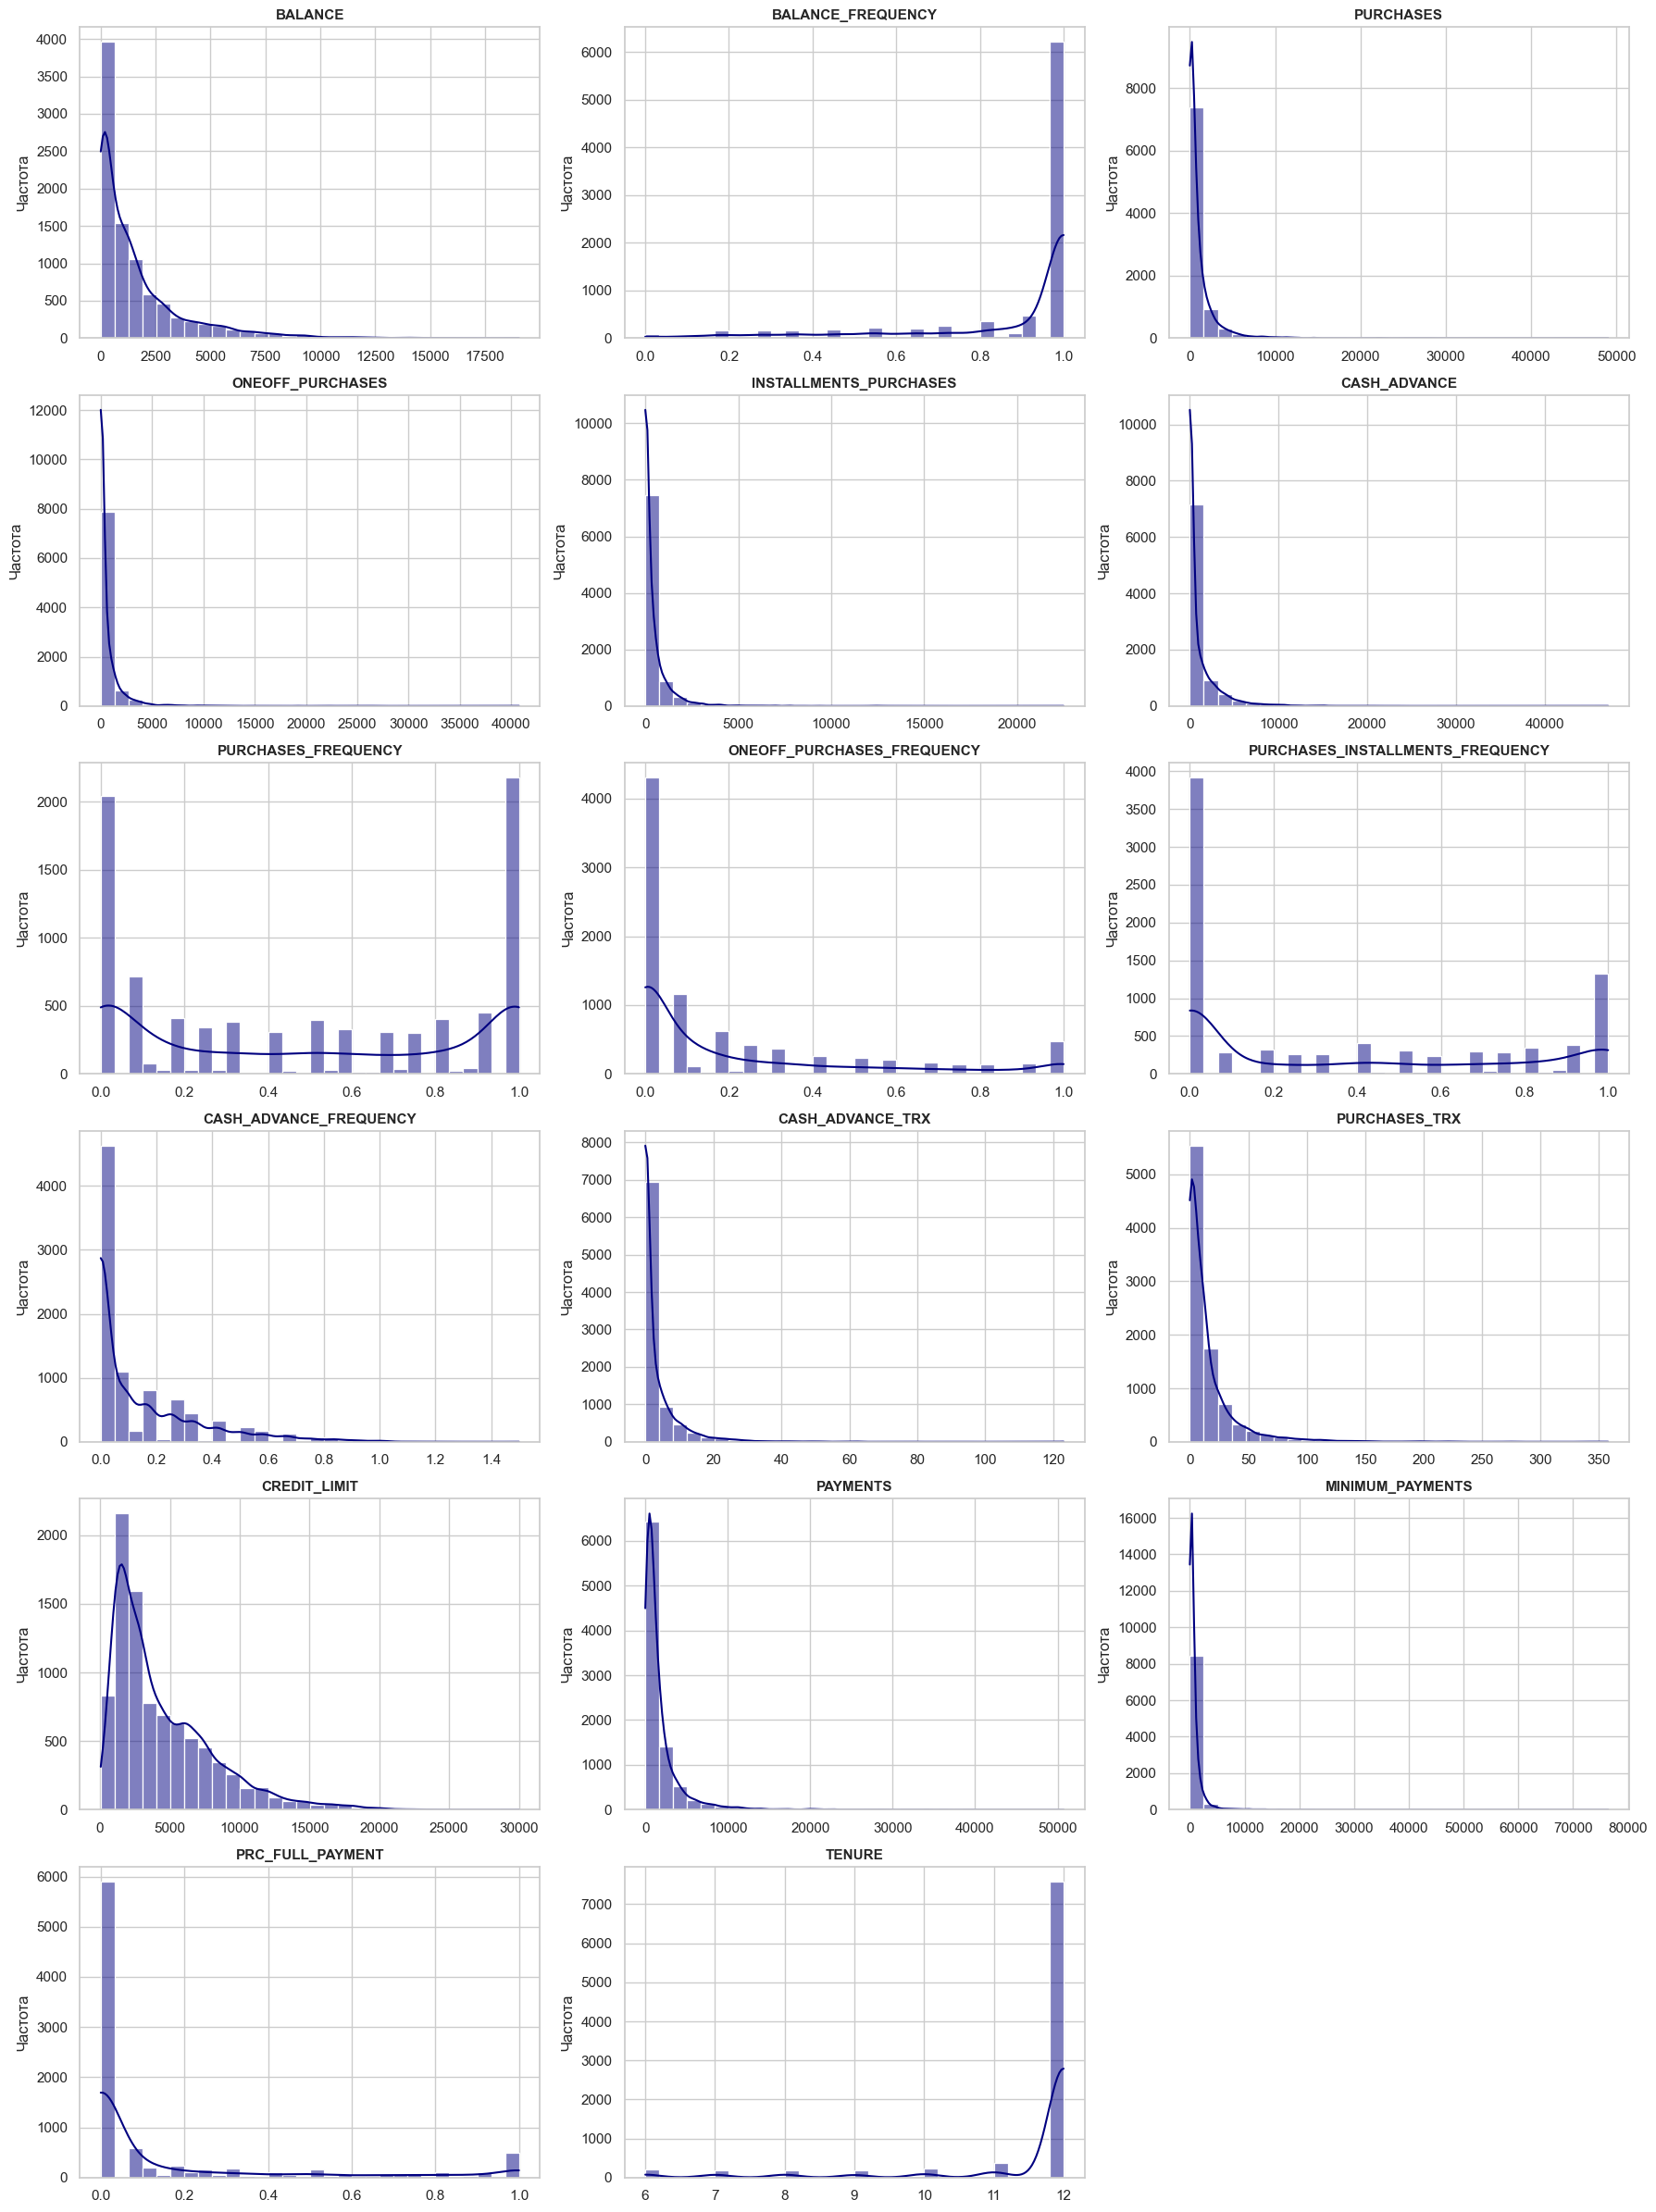

In [10]:
skewness = df_cleaned.skew().sort_values(ascending=False)
skew_table = pd.DataFrame({'Коэффициент асимметрии (Skewness)': skewness}).round(2)
display(skew_table)

all_features = df_cleaned.columns.tolist()

fig, axes = plt.subplots(6, 3, figsize=(18, 24))
axes = axes.flatten()

for i, col in enumerate(all_features):
    sns.histplot(df_cleaned[col], kde=True, ax=axes[i], color='navy', bins=30)
    axes[i].set_title(f"{col}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Частота")

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

Визуальный анализ гистограмм и расчетных коэффициентов асимметрии показывает полное отсутствие признаков с классическим нормальным (гауссовским) распределением. Все переменные можно четко структурировать по характеру их асимметрии:

#### 1. Экстремальная правосторонняя асимметрия:
К этой группе относится абсолютное большинство монетарных и счетных показателей:
- **Абсолютные лидеры по аномалиям:** `MINIMUM_PAYMENTS` ($Skew = 13.85$) и `ONEOFF_PURCHASES` ($Skew = 10.05$). На гистограммах виден гигантский столбец около нуля и длиннейший пустой шлейф редких выбросов справа.
- **Транзакционные и платежные объемы:** `PURCHASES` ($8.14$), `INSTALLMENTS_PURCHASES` ($7.30$), `PAYMENTS` ($5.91$), `CASH_ADVANCE_TRX` ($5.72$), `CASH_ADVANCE` ($5.17$), `PURCHASES_TRX` ($4.63$) и `BALANCE` ($2.39$).
- **Экономический смысл:** Подавляющее большинство клиентов либо не пользуются определенными услугами вовсе (снятие наличных, покупки в рассрочку), либо оперируют малыми суммами, в то время как единичные клиенты генерируют колоссальные объемы.

#### 2. Левосторонняя асимметрия:
В датасете присутствуют два признака с сильным смещением массы данных в правую часть шкалы:
- `TENURE` ($Skew = -2.94$): Распределение дискретно, более $80\%$ клиентов пользуются картой максимальный срок — $12$ месяцев.
- `BALANCE_FREQUENCY` ($Skew = -2.02$): Около $70\%$ клиентов имеют показатель $1.0$, то есть банк обновляет баланс по их счету непрерывно.

#### 3. Специфические частотные и дискретные распределения:
- **`PURCHASES_FREQUENCY` ($Skew = 0.06$):** Формально коэффициент асимметрии близок к нулю, однако распределение категорически **не является нормальным**. На графике видна четкая **U-образная (бимодальная)** форма: клиенты полярно делятся на тех, кто вообще не совершает покупки картой (пик в точке $0.0$), и тех, кто оплачивает картой абсолютно все (пик в точке $1.0$).
- `PRC_FULL_PAYMENT` ($Skew = 1.94$): Около $6 000$ клиентов никогда не гасят задолженность целиком ($0.0$), и лишь небольшая обособленная группа закрывает баланс в $100\%$ ($1.0$).
- `CREDIT_LIMIT` ($Skew = 1.52$): Имеет ступенчатое распределение, отражающее банковскую сетку одобрения стандартных лимитов (\$1 000, \$3 000, \$5 000) с угасанием к \$30 000.

### Вывод о применимости методов кластеризации:
1. **Неприменимость метрик без предварительной обработки:** Так как большинство признаков имеют колоссальный правый хвост, стандартное евклидово расстояние в сырых данных будет на $99\%$ определяться только масштабом `MINIMUM_PAYMENTS`, `PAYMENTS` и `CREDIT_LIMIT`. Признаки с масштабом от $0$ до $1$ (частоты) просто обратятся в статистический шум с нулевым весом.
2. **Необходимость масштабирования:** Использование `StandardScaler` является строго обязательным условием для перевода всех 17 разнородных шкал в сопоставимый безразмерный вид.

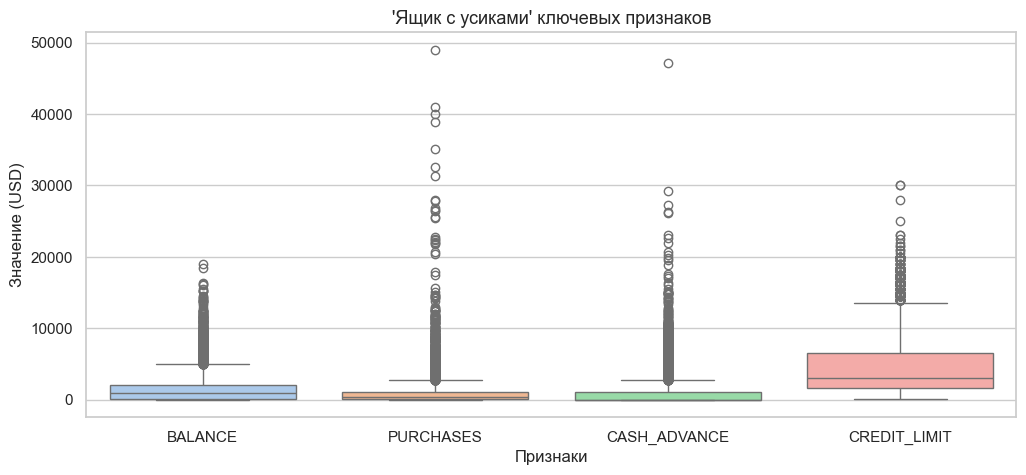

In [16]:
plt.figure(figsize=(12, 5))
sns.boxplot(
    data=df_cleaned[['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT']], 
    palette="pastel"
)
plt.title("'Ящик с усиками' ключевых признаков", fontsize=13)
plt.ylabel("Значение (USD)")
plt.xlabel("Признаки")
plt.show()

1. **Отсутствие априорной разметки (классов):** В рассматриваемом датасете изначально нет целевой переменной ($y$) или заранее известных меток классов. Задача носит исключительно исследовательский характер — выявить скрытые группы клиентов по их финансовому поведению.
2. **Осмысленность задачи:** Сегментация держателей карт имеет прямую практическую ценность для банка. Полученные группы позволят персонализировать кредитные лимиты, оптимизировать программы кэшбэка и выявлять неактивных пользователей.
3. **Наличие выбросов:** 
   - На диаграмме размаха видно огромное количество точек далеко за пределами верхних «усов».
   - Данные точки не являются ошибками ввода или сбоями — это реальные клиенты с нетипично крупными оборотами (VIP-сегмент).
   - Удалять их нельзя, так как они важны для бизнеса, однако из-за сильного разброса значений обычные метрики расстояния (евклидово расстояние) будут искажены. Это подтверждает жесткую необходимость стандартизации данных перед переходом к алгоритмам кластеризации.

In [18]:
scaler = StandardScaler()
scaled_array = scaler.fit_transform(df_cleaned)
df_scaled = pd.DataFrame(scaled_array, columns=df_cleaned.columns)
check_scaling = pd.DataFrame({
    'Исходный диапазон': [f"[{df_cleaned['BALANCE'].min():.0f}, {df_cleaned['BALANCE'].max():.0f}]"],
    'Масштабированный средний (Mean)': [df_scaled['BALANCE'].mean().round(4)],
    'Масштабированная дисперсия (Std)': [df_scaled['BALANCE'].std().round(4)]
}, index=['BALANCE'])

display(check_scaling)

,Исходный диапазон,Масштабированный средний (Mean),Масштабированная дисперсия (Std)
BALANCE,"[0, 19043]",-0.0,1.0001


1. **Почему `StandardScaler`, а не `MinMaxScaler`:**
   - При наличии выявленных ранее экстремальных выбросов метод нормализации в отрезок $[0, 1]$ (`MinMaxScaler`) сжал бы 99% всех наблюдений в микроскопический диапазон $[0; 0.05]$, сделав клиентов неотличимыми друг от друга.
   - `StandardScaler` центрирует облако точек относительно нуля с дисперсией $\sigma^2 = 1$, сохраняя взаимную геометрию расстояний между объектами.
2. **Влияние на кластеризацию:** Без стандартизации признак `CREDIT_LIMIT` (значения до \$30 000) полностью подавил бы признаки частот (значения от 0 до 1), сведя многомерную кластеризацию к группировке по единственной шкале лимита.

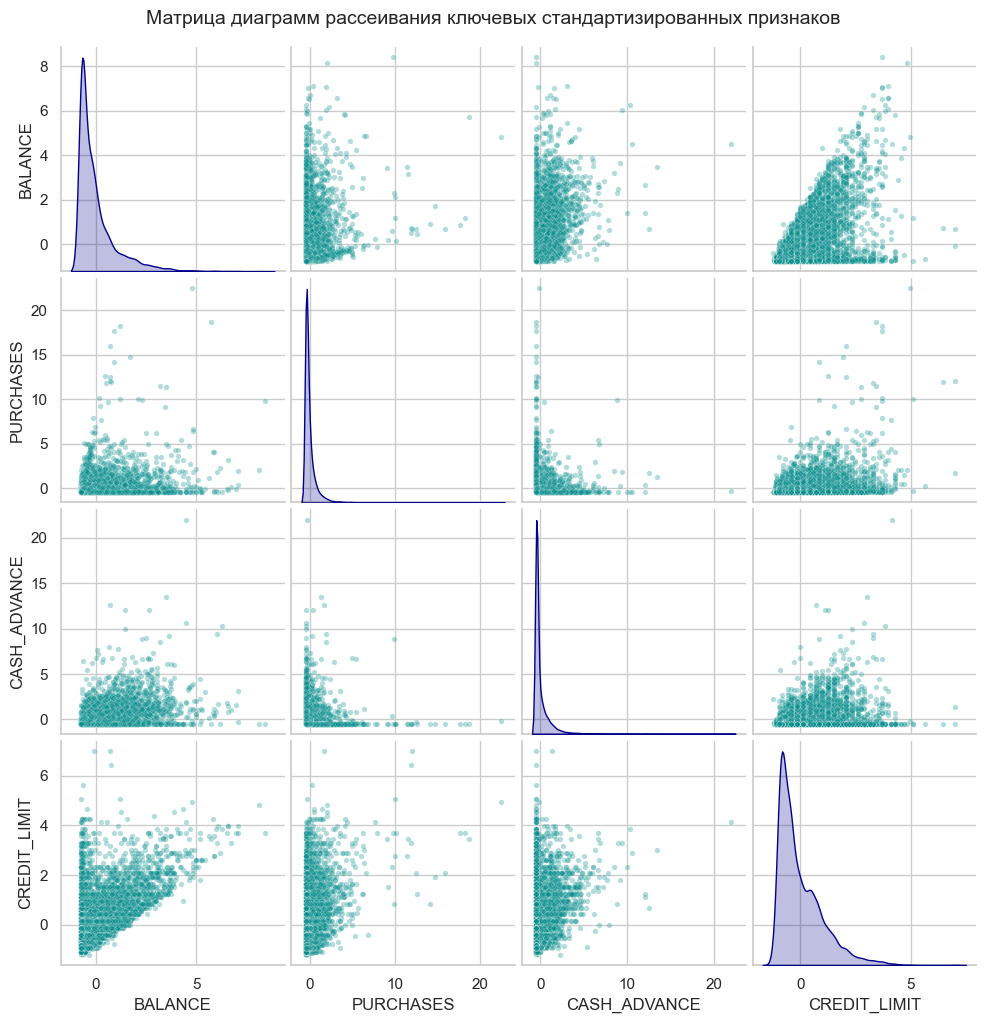

In [19]:
core_dimensions = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT']
pairplot_fig = sns.pairplot(
    df_scaled[core_dimensions], 
    diag_kind='kde',
    plot_kws={'alpha': 0.3, 's': 15, 'color': 'darkcyan'},
    diag_kws={'color': 'darkblue', 'fill': True}
)
pairplot_fig.fig.suptitle("Матрица диаграмм рассеивания ключевых стандартизированных признаков", y=1.02, fontsize=14)
plt.show()

Визуальная оценка парных проекций (по ключевым признакам, потому что анализ пар абсолютно всех признаков был бы нерациональным использованием программных и интеллектуальных ресурсов) позволяет сделать ключевые выводы о структуре многомерного пространства:
1. **Плотность и форма скоплений:**
   - Наблюдается сверхплотное ядро в районе начала координат $(0, 0)$. Это основная масса рядовых клиентов со средними и околонулевыми операционными показателями.
   - От центрального ядра отходят выраженные **веерообразные и L-образные лучи** вдоль координатных осей. Например:
     - Пара `PURCHASES` vs `CASH_ADVANCE` четко показывает разделение: клиенты, совершающие много покупок, практически не снимают наличные в долг, и наоборот. Данные расходятся под прямым углом.
2. **Тип кластерной структуры:**
   - Кластеры **не являются** сферическими, изолированными «шарами» равного размера.
   - Структура данных представляет собой непрерывное пространство с неоднородной плотностью и ярко выраженными ортогональными "лучами", вытянутыми эллипсами.
3. **Предположительное количество кластеров:**
   - Визуально прослеживаются как минимум **3–4 поведенческих паттерна**:
     1. Клиенты с доминированием безналичных покупок (`High PURCHASES`);
     2. Клиенты с доминированием кредитных наличных (`High CASH_ADVANCE`);
     3. VIP-сегмент (или кредитные рабы);
     4. Массовый низкоактивный сегмент вокруг нуля.

## Причины исключения альтернативных алгоритмов:

* **Иерархическая кластеризация — отклонена из-за вычислительной неэффективности:**
  - Алгоритм требует вычисления и хранения в оперативной памяти полной матрицы попарных расстояний размерностью $N \times N$. Для выборки $N = 8\,950$ объектов это составляет $\approx 8 \times 10^7$ элементов, что дает алгоритмическую сложность $O(N^2)$ по памяти и до $O(N^3)$ по времени. 
  - Построение дендрограммы на 9 тысячах объектов делает её нечитаемой для аналитика и неоправданно ресурсоемкой.

* **DBSCAN — отклонен:**
  - DBSCAN опирается на предположение о равномерной плотности кластеров при фиксированном радиусе соседства $\varepsilon$.
  - Из-за колоссального перепада плотности между массовым сегментом и премиальным ядром подбор гиперпараметра $\varepsilon$ приводит к двум патологиям:
    1. При малом $\varepsilon$: активные и платежеспособные клиенты с высокими чеками на концах распределений будут ошибочно помечены как шум / выбросы (метка `-1`).
    2. При большом $\varepsilon$: ядро данных сольется в единый неинформативный гиперкластер, скрыв внутреннюю сегментацию.

### Выбор целевых алгоритмов для исследования:

Для практической реализации выбраны два метода, оптимально подходящие под выявленные геометрические и вычислительные ограничения:

1. **K-Means (Метод K-средних) — простая базовая модель:**
   - **Скорость и простота:** Это самый популярный и быстрый алгоритм. Массив из 9 000 строк он обработает буквально за секунды.
   - **Понятный результат:** Каждый кластер описывается его центром — то есть простым «среднестатистическим портретом» клиента (например: *«в этой группе средний баланс $1000, а покупки $200»*). Это удобно объяснять бизнесу.
   - Мы берем K-Means в качестве точки отсчета, чтобы проверить, насколько хорошо сработает стандартный подход.

2. **EM-алгоритм (Gaussian Mixture) — продвинутый метод под нашу форму данных:**
   - **Хорош для данных, сильно вытянутых вдоль осей:** На графиках рассеивания четко видно, что наши точки не лежат круглыми островками. Они **сильно вытянуты в длинные «хвосты» вдоль конкретных шкал** (например, клиенты с огромными покупками `PURCHASES` вытягиваются тонкой полосой вверх вдоль вертикальной оси, оставаясь около нуля по снятию наличных).
   - **В чем преимущество перед K-Means:** K-Means слепо считает, что кластеры обязаны быть идеально *круглыми шарами*. Из-за этого он пытается разрезать наши длинные вытянутые ветви поперек, деля единый поток клиентов на неестественные куски. EM-алгоритм, напротив, умеет настраивать **вытянутые эллипсы (овалы) любой длины и под любым углом**, за счет чего он повторяет реальную форму вытянутых финансовых трат.

## Кластеризация методом K-Means

### Подбор оптимального числа кластеров $k$ (Метод локтя и Анализ силуэта)
Для подбора параметра $k$ исследуем диапазон от 2 до 8 кластеров. Оценку качества проведем по двум взаимодополняющим критериям:
1. **Метод локтя:** Сумма квадратов расстояний от объектов до центроидов их кластеров (внутрикластерная компактность).
2. **Коэффициент силуэта:** Мера разделения кластеров, сопоставляющая среднее внутрикластерное расстояние со средним расстоянием до ближайшего соседнего кластера.

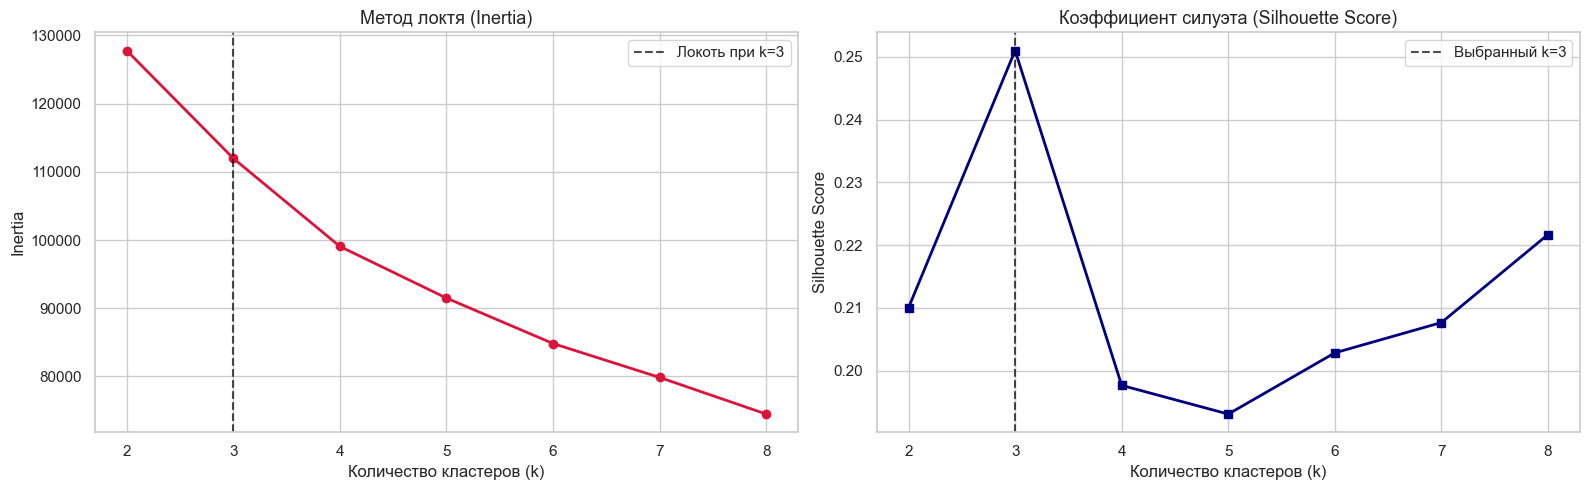

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

k_range = range(2, 9)
inertia_values = []
silhouette_values = []
davies_bouldin_values = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(df_scaled)
    
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(df_scaled, kmeans.labels_))
    davies_bouldin_values.append(davies_bouldin_score(df_scaled, kmeans.labels_))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(k_range, inertia_values, marker='o', color='crimson', linewidth=2)
axes[0].set_title("Метод локтя (Inertia)", fontsize=13)
axes[0].set_xlabel("Количество кластеров (k)")
axes[0].set_ylabel("Inertia")
axes[0].axvline(x=3, color='black', linestyle='--', alpha=0.7, label='Локоть при k=3')
axes[0].legend()

axes[1].plot(k_range, silhouette_values, marker='s', color='navy', linewidth=2)
axes[1].set_title("Коэффициент силуэта (Silhouette Score)", fontsize=13)
axes[1].set_xlabel("Количество кластеров (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].axvline(x=3, color='black', linestyle='--', alpha=0.7, label='Выбранный k=3')
axes[1].legend()

plt.tight_layout()
plt.show()

- График коэффициента силуэта (Silhouette Score) демонстрирует **выраженный глобальный максимум при $k = 3$**. 
- При попытке увеличения числа кластеров до $k = 4$ наблюдается резкая деградация силуэта (падение до $< 0.20$), что свидетельствует об искусственном дроблении естественно неделимых групп.
- График метода локтя также подтверждает, что основной прирост компактности достигается при переходе от 2 к 3 кластерам, после чего скорость снижения инерции замедляется.
- **Итоговое решение:** Выбрано разбиение на **$k = 3$ кластера**, как являющееся строго оптимальным с математической точки зрения и формирующее три фундаментальных сегмента банковских клиентов.

### Особенности оценки качества в обучении без учителя:
- **Внешние метрики:** Метрики сходства с эталоном, такие как *Индекс Рэнда*, *Индекс Жаккара* **не применимы**, так как в банковском датасете отсутствует априорная разметка.
- **Внутренние метрики (Internal Evaluation):** Качество оценивается исключительно по геометрии распределения объектов в признаковом пространстве:
  1. **Коэффициент силуэта:** Измеряет степень принадлежности объекта к своему кластеру относительно соседних;
  2. **Индекс Дэвиса-Болдина:** Среднее отношение внутрикластерного расстояния к межкластерному;
  3. **Индекс Калински-Харабаса:** Дисперсионное отношение межкластерного разброса к внутрикластерному;
  4. **Инерция:** Сумма квадратов расстояний до центроидов (показатель компактности).

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.spatial.distance import cdist

k_chosen = 3
kmeans_3 = KMeans(n_clusters=k_chosen, init='k-means++', n_init=10, random_state=42)
labels_3 = kmeans_3.fit_predict(df_scaled)

wcss_3 = kmeans_3.inertia_
sil_3 = silhouette_score(df_scaled, labels_3)
db_3 = davies_bouldin_score(df_scaled, labels_3)
ch_3 = calinski_harabasz_score(df_scaled, labels_3)

metrics_df = pd.DataFrame({
    'Метрика': [
        'Инерция',
        'Коэффициент силуэта (Silhouette Score)',
        'Индекс Дэвиса-Болдина',
        'Индекс Калински-Харабаса'
    ],
    'Значение': [wcss_3, sil_3, db_3, ch_3],
    'Критерий оптимальности': ['Минимум', 'Максимум (+1)', 'Минимум (0)', 'Максимум']
})

display(metrics_df.round(3))

,Метрика,Значение,Критерий оптимальности
0,Инерция,111975.044,Минимум
1,Коэффициент силуэта (Silhouette Score),0.251,Максимум (+1)
2,Индекс Дэвиса-Болдина,1.592,Минимум (0)
3,Индекс Калински-Харабаса,1605.026,Максимум


### Интерпретация полученных метрик качества:
- **Silhouette Score ($0.251$):** Значение положительно и существенно отличается от нуля, что свидетельствует об обнаружении устойчивых кластерных структур. Для многомерных непрерывных финансовых данных с гиперплотным ядром значение в районе $0.25–0.30$ является репрезентативным показателем адекватного разбиения (отсутствуют наложения кластеров друг на друга).
- **Индекс Дэвиса-Болдина ($1.592$):** Значение $< 2$ подтверждает, что диаметры полученных кластеров сопоставимы или меньше расстояний между их центрами.
- **Индекс Калински-Харабаса ($1605$):** Высокое значение указывает на то, что дисперсия центров кластеров относительно общего центра масс существенно превышает дисперсию точек внутри отдельных групп.

In [23]:
centroids_scaled = kmeans_3.cluster_centers_

inter_cluster_dist = cdist(centroids_scaled, centroids_scaled, metric='euclidean')
df_inter_dist = pd.DataFrame(
    inter_cluster_dist, 
    columns=[f'Кластер {i}' for i in range(k_chosen)],
    index=[f'Кластер {i}' for i in range(k_chosen)]
)

intra_cluster_dist = []
for i in range(k_chosen):
    cluster_points = df_scaled[labels_3 == i].values
    distances_to_centroid = np.linalg.norm(cluster_points - centroids_scaled[i], axis=1)
    intra_cluster_dist.append(distances_to_centroid.mean())

df_compactness = pd.DataFrame({
    'Кластер': [f'Кластер {i}' for i in range(k_chosen)],
    'Размер кластера (чел.)': np.bincount(labels_3),
    'Доля выборки (%)': (np.bincount(labels_3) / len(df_scaled) * 100).round(1),
    'Внутрикластерное расстояние (Компактность)': np.round(intra_cluster_dist, 3)
})

print("1. Матрица расстояний между центроидами кластеров:")
display(df_inter_dist.round(3))

print("\n2. Оценка размеров и компактности кластеров:")
display(df_compactness)

1. Матрица расстояний между центроидами кластеров:


,Кластер 0,Кластер 1,Кластер 2
Кластер 0,0.000,4.504,5.626
Кластер 1,4.504,0.000,3.806
Кластер 2,5.626,3.806,0.000



2. Оценка размеров и компактности кластеров:


,Кластер,Размер кластера (чел.),Доля выборки (%),Внутрикластерное расстояние (Компактность)
0,Кластер 0,1275,14.2,4.236
1,Кластер 1,6114,68.3,2.642
2,Кластер 2,1561,17.4,3.540


1. **Межкластерная обособленность:** 
   - Наиболее удалены друг от друга Кластер 0 и Кластер 2 (расстояние между центрами $\approx 5.6$), что указывает на кардинально противоположные поведенческие паттерны групп.
   - Минимальное расстояние наблюдается между ядром (Кластер 1) и периферией, что полностью согласуется с непрерывной природой клиентской базы.
2. **Компактность (дисперсия):** 
   - Самый многочисленный сегмент (Кластер 1, объединяющий более 65% клиентов) является **наиболее компактным** (средний радиус $\approx 2.6$). Это подтверждает обнаруженное ранее гиперплотное ядро рядовых клиентов.
   - Малочисленные группы имеют больший разброс (радиус $\approx 3.5-4.2$) из-за наличия премиальных выбросов с крупными лимитами и чеками.

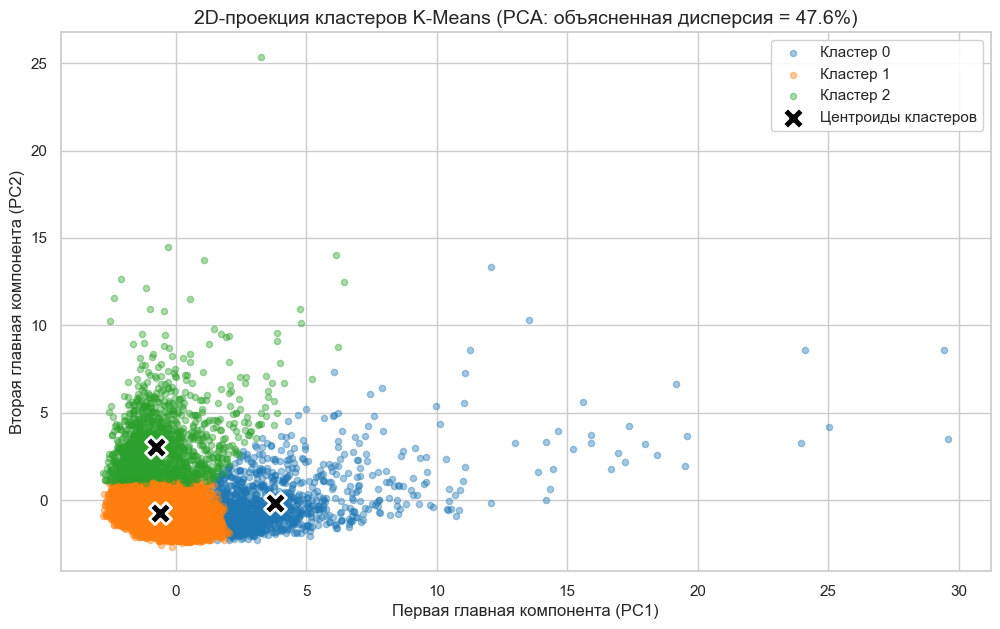

In [25]:
from sklearn.decomposition import PCA
pca_2d = PCA(n_components=2, random_state=42)
principal_components = pca_2d.fit_transform(df_scaled)
centroids_pca = pca_2d.transform(centroids_scaled)
plt.figure(figsize=(12, 7))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i in range(k_chosen):
    plt.scatter(
        principal_components[labels_3 == i, 0],
        principal_components[labels_3 == i, 1],
        s=20, alpha=0.4, color=palette[i],
        label=f'Кластер {i}'
    )

plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    s=250, c='black', marker='X', edgecolor='white', linewidth=2,
    label='Центроиды кластеров'
)

plt.title(
    f"2D-проекция кластеров K-Means (PCA: объясненная дисперсия = {pca_2d.explained_variance_ratio_.sum():.1%})",
    fontsize=14
)
plt.xlabel("Первая главная компонента (PC1)")
plt.ylabel("Вторая главная компонента (PC2)")
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.show()

### Интерпретация результатов 2D-проекции кластеров:

- Две главные компоненты смогли аккумулировать в себе 47,6% суммарной информации исходного пространства
- На графике наглядно видна топология разбиения:
  - **Кластер 1 (оранжевый):** Сконцентрирован в плотном ядре в нижней левой части проекции (около нуля). Это наименее дисперсная и самая многочисленная группа клиентов со стандартным неактивным поведением.
   - **Кластер 0 (синий):** Направлен строго вправо вдоль горизонтальной оси **PC1**. Данная компонента коррелирует с объемами безналичных трат: точки образуют протяженный шлейф активных покупателей с высокими суммами транзакций.
   - **Кластер 2 (зеленый):** Направлен вертикально вверх вдоль оси **PC2**. Данная компонента отражает кредитную нагрузку: здесь сосредоточены заемщики с максимальными суммами снятия наличных (`CASH_ADVANCE`) и высоким остатком долга.
- Метод K-Means четко разделил веерообразные лучи, найденные нами на этапе матричных диаграмм рассеивания.

In [26]:
centroids_real = scaler.inverse_transform(centroids_scaled)
df_centroids = pd.DataFrame(centroids_real, columns=df_cleaned.columns)

profile_cols = [
    'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
    'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'CREDIT_LIMIT', 'PAYMENTS', 'PRC_FULL_PAYMENT'
]

cluster_profiles = df_centroids[profile_cols].T
cluster_profiles.columns = [f'Кластер {i}' for i in range(k_chosen)]

cluster_profiles['Среднее по банку'] = df_cleaned[profile_cols].mean()

display(cluster_profiles.round(1))

,Кластер 0,Кластер 1,Кластер 2,Среднее по банку
BALANCE,2181.0,807.6,4025.6,1564.5
PURCHASES,4183.4,495.5,389.3,1003.2
ONEOFF_PURCHASES,2661.5,247.0,252.5,592.4
INSTALLMENTS_PURCHASES,1522.4,248.9,136.9,411.1
CASH_ADVANCE,449.2,339.1,3919.4,978.9
PURCHASES_FREQUENCY,0.9,0.5,0.2,0.5
CREDIT_LIMIT,7635.7,3266.7,6733.0,4494.3
PAYMENTS,4072.8,906.9,3055.5,1733.1
PRC_FULL_PAYMENT,0.3,0.2,0.0,0.2


## Содержательная экономическая интерпретация центров кластеров

Дестандартизация координат центроидов позволила перевести абстрактные значения расстояний в реальные финансовые показатели (доллары США и частоты операций). 

Сравнение полученных центров со средними значениями по банку выявило три четко выраженных, фундаментально различных типа экономического поведения клиентов:

### Кластер 0: «Активные потребители / VIP-транжиры»
* **Фактический профиль:**
  - **Объем покупок (`PURCHASES`):** **\$4 183.4** (в 4.2 раза выше среднего по банку \$1 003.2);
  - **Частота покупок (`PURCHASES_FREQUENCY`):** **0.9** (совершают покупки практически ежедневно);
  - **Структура трат:** Высокие траты как на разовые крупные покупки (`ONEOFF_PURCHASES` = \$2 661.5), так и на оплату в рассрочку (`INSTALLMENTS_PURCHASES` = \$1 522.4);
  - **Кредитный лимит (`CREDIT_LIMIT`):** **\$7 635.7** (максимальный среди всех групп);
  - **Снятие наличных (`CASH_ADVANCE`):** всего \$449.2 (в 2 раза ниже среднего);
  - **Дисциплина погашения:** Самая высокая доля полного закрытия долга (`PRC_FULL_PAYMENT` = 0.3) при платежах в \$4 072.8.
* **Экономический смысл для банка:** Премиальная, финансово грамотная аудитория с высоким доходом. Карта используется как основной платежный инструмент.

### Кластер 1: «Массовый экономный сегмент / Осторожные пользователи»
* **Фактический профиль:**
  - **Баланс задолженности (`BALANCE`):** **\$807.6** (вдвое ниже среднего показателя);
  - **Объем покупок (`PURCHASES`):** **\$495.5** в год при умеренной частоте 0.5 (эпизодические мелкие чеки);
  - **Снятие наличных (`CASH_ADVANCE`):** **\$339.1** (минимальный показатель по всей выборке);
  - **Кредитный лимит (`CREDIT_LIMIT`):** **\$3 266.7** (минимальный среди всех сегментов);
  - **Платежи (`PAYMENTS`):** \$906.9 (покрывают текущие небольшие траты).
* **Экономический смысл для банка:** Самый низкорисковый, но наименее доходный сегмент. Клиенты держат карту «на черный день» или совершают бытовые покупки, строго контролируя расходы и не выходя в процентные долги.

### Кластер 2: «Рисковые ребята»
* **Фактический профиль:**
  - **Баланс задолженности (`BALANCE`):** **\$4 025.6** (в 2.6 раза выше среднего по банку);
  - **Снятие наличных (`CASH_ADVANCE`):** **\$3 919.4** (в 4 раза превышает среднее по банку!);
  - **Объем покупок (`PURCHASES`):** всего **\$389.3** при минимальной частоте операций (0.2);
  - **Кредитный лимит (`CREDIT_LIMIT`):** **\$6 733.0** (высокий лимит, выбранный почти на 60% наличными);
  - **Дисциплина погашения (`PRC_FULL_PAYMENT`):** **0.0 (строго ноль!)** — клиенты никогда не закрывают задолженность целиком, внося лишь минимальные платежи (`PAYMENTS` = \$3 055.5).
* **Экономический смысл для банка:** Высокодоходный, но **критически рискованный** сегмент. Клиенты используют карту не для покупок, а как микрофинансовый инструмент экстренного обналичивания средств под высокие проценты. Генерируют максимальный процентный доход и комиссии за снятие в банкоматах, но несут колоссальный риск невозврата долга.
